# 01 · Data understanding, validation split and conversion

VisDrone2019-VID: 8 classes, drone video, small and dense objects.
This notebook explores the data, fixes the validation protocol and builds the YOLO-format dataset that the next notebooks train on.

**Run on Kaggle:** attach the competition data, CPU is enough (no GPU needed), then *Save Version → Save & Run All*.
The output folder (`vd_yolo/`, `vd_utils.py`, `eda/`) is added as input to the next notebooks.

In [1]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    return {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub

Writing vd_utils.py


In [2]:
# setup
import json, random, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import vd_utils as vd

SEED = 42
random.seed(SEED); np.random.seed(SEED)
ROOT = vd.find_data_root()
WORK = Path("/kaggle/working")
(WORK / "eda").mkdir(exist_ok=True)
CLASSES = vd.CLASSES
pd.set_option("display.precision", 3)
print("data root:", ROOT)

imgs = {}; anns = {}
for split in ["train", "val"]:
    imgs[split], anns[split] = vd.load_split(ROOT, split)
test = pd.read_csv(ROOT / "test_images.csv")

data root: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Overview and sequence-level split

In [3]:
rows = {}
for s in ["train", "val"]:
    a = anns[s]; obj = a[a.iscrowd == 0]
    rows[s] = {"clips": imgs[s]["clip"].nunique(), "frames": len(imgs[s]), "objects": len(obj),
               "ignored regions": int((a.iscrowd == 1).sum()), "objects / frame": len(obj) / len(imgs[s])}
rows["test"] = {"clips": test["clip"].nunique(), "frames": len(test)}
display(pd.DataFrame(rows).T)

# validation = the organisers' val/ folder: 7 whole clips, no clip shared with train
shared = set(imgs["train"]["clip"]) & set(imgs["val"]["clip"])
print("clips in both train and val:", len(shared))

,clips,frames,objects,ignored regions,objects / frame
train,56.0,24201.0,1.106e+06,510744.0,45.681
val,7.0,2846.0,1.141e+05,31960.0,40.103
test,48.0,3811.0,NaN,NaN,NaN


clips in both train and val: 0


## 2. Class distribution

,train,val,train %,val %
person,328701,50312,29.7,44.1
bicycle,40255,6022,3.6,5.3
car,505301,31821,45.7,27.9
van,46940,6842,4.2,6.0
truck,30498,1359,2.8,1.2
tricycle,41349,5487,3.7,4.8
bus,9653,264,0.9,0.2
motor,102819,12025,9.3,10.5


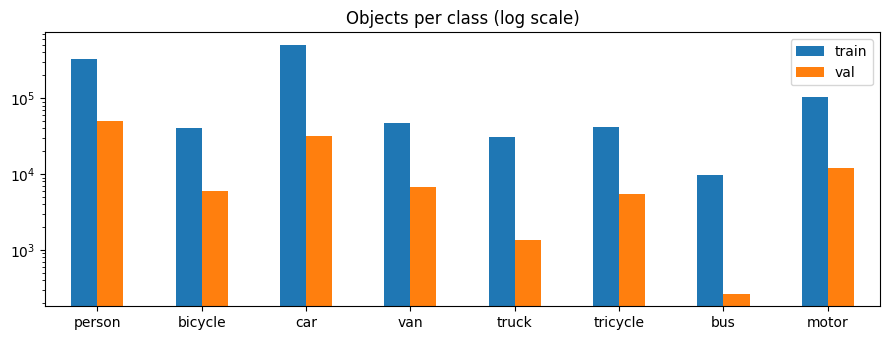

In [4]:
obj = {s: anns[s][anns[s].iscrowd == 0] for s in ["train", "val"]}
cls = pd.DataFrame({s: obj[s].cls.value_counts().reindex(range(8), fill_value=0) for s in obj})
cls.index = CLASSES
cls_pct = (cls / cls.sum() * 100).round(1).add_suffix(" %")
display(pd.concat([cls, cls_pct], axis=1))

ax = cls.plot.bar(figsize=(9, 3.5), logy=True, rot=0, title="Objects per class (log scale)")
plt.tight_layout(); plt.savefig(WORK / "eda/class_counts.png", dpi=120); plt.show()

## 3. Object sizes
COCO buckets: small < 32² px, medium < 96² px, large ≥ 96². These buckets define AP_small / AP_medium / AP_large.

size percentiles (px): {0.05: 19.7, 0.25: 32.0, 0.5: 45.8, 0.75: 67.9, 0.95: 130.2}
overall share by bucket, %: {'medium': 63.5, 'small': 24.9, 'large': 11.6}


bucket,small,medium,large,median_px
cls,,,,
bicycle,24.4,74.1,1.5,41.4
bus,4.1,39.0,56.9,113.4
car,16.3,64.5,19.2,57.0
motor,30.4,68.2,1.4,40.2
person,39.5,60.2,0.3,35.8
tricycle,21.0,66.1,12.8,54.9
truck,9.4,57.9,32.7,73.5
van,21.4,62.7,15.9,49.8


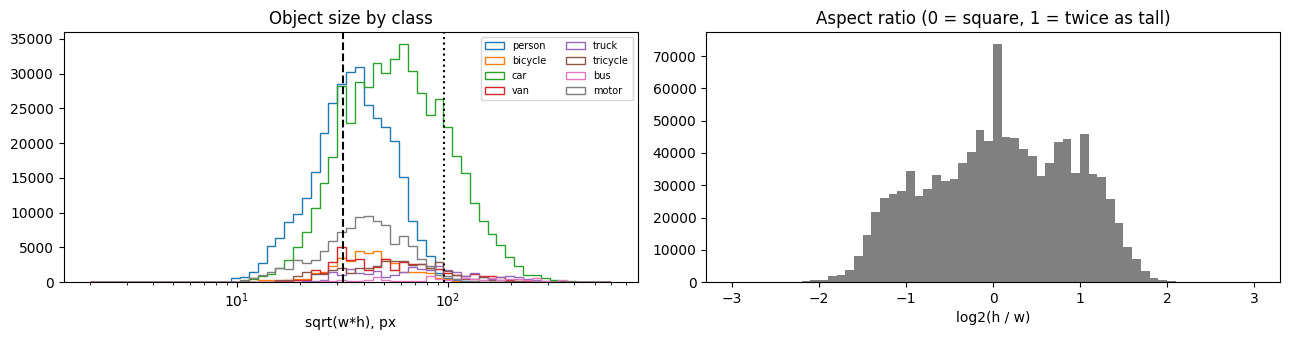

In [5]:
o = obj["train"].copy()
o["size"] = np.sqrt(o.w * o.h)                       # side of a square with the same area, px
o["bucket"] = pd.cut(o.w * o.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)
o["aspect"] = o.h / o.w

print("size percentiles (px):", o["size"].quantile([.05, .25, .5, .75, .95]).round(1).to_dict())
display(pd.crosstab(o.cls.map(dict(enumerate(CLASSES))), o.bucket, normalize="index").mul(100).round(1)
        .assign(median_px=o.groupby(o.cls.map(dict(enumerate(CLASSES))))["size"].median().round(1)))
print("overall share by bucket, %:", o.bucket.value_counts(normalize=True).mul(100).round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
bins = np.logspace(np.log10(2), np.log10(600), 60)
for c in range(8):
    ax[0].hist(o.loc[o.cls == c, "size"], bins=bins, histtype="step", lw=1.5, label=CLASSES[c])
ax[0].set_xscale("log"); ax[0].axvline(32, c="k", ls="--"); ax[0].axvline(96, c="k", ls=":")
ax[0].set_xlabel("sqrt(w*h), px"); ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Object size by class")
ax[1].hist(np.log2(o.aspect.clip(1/8, 8)), bins=60, color="gray")
ax[1].set_xlabel("log2(h / w)"); ax[1].set_title("Aspect ratio (0 = square, 1 = twice as tall)")
plt.tight_layout(); plt.savefig(WORK / "eda/object_sizes.png", dpi=120); plt.show()

## 4. Scene density: objects per frame

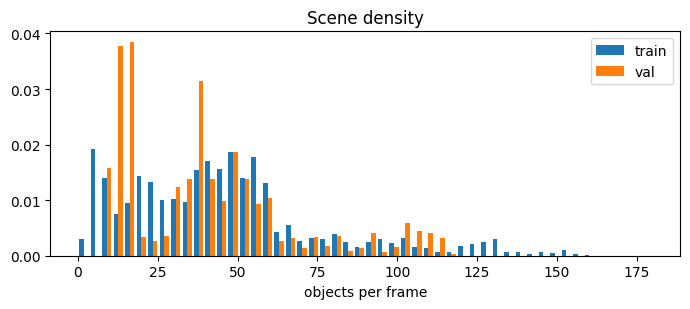

In [6]:
dens = {s: obj[s].groupby("image_id").size().reindex(imgs[s].image_id, fill_value=0) for s in obj}
for s, d in dens.items():
    print(f"{s}: median {d.median():.0f}, 95% {d.quantile(.95):.0f}, max {d.max()} objects per frame")

plt.figure(figsize=(7, 3.2))
plt.hist([dens["train"], dens["val"]], bins=50, density=True, label=["train", "val"])
plt.xlabel("objects per frame"); plt.legend(); plt.title("Scene density")
plt.tight_layout(); plt.savefig(WORK / "eda/density.png", dpi=120); plt.show()

## 5. How clips differ

,split,resolution,frames,obj/frame,median px,% small,top class
clip,,,,,,,
uav0000138_00000_v,train,2688x1512,213,143.0,45.4,17.2,car
uav0000126_00001_v,train,2688x1512,412,132.2,48.4,24.3,car
uav0000124_00944_v,train,2688x1512,398,124.6,46.3,24.2,car
uav0000072_04488_v,train,1904x1071,85,110.4,45.8,14.7,person
uav0000150_02310_v,train,2688x1512,348,108.9,60.0,5.1,motor
...,...,...,...,...,...,...,...
uav0000099_02109_v,train,1344x756,1255,7.1,37.1,28.7,person
uav0000266_03598_v,train,2688x1512,548,6.5,80.9,0.0,car
uav0000263_03289_v,train,1904x1071,725,6.5,54.9,11.2,truck


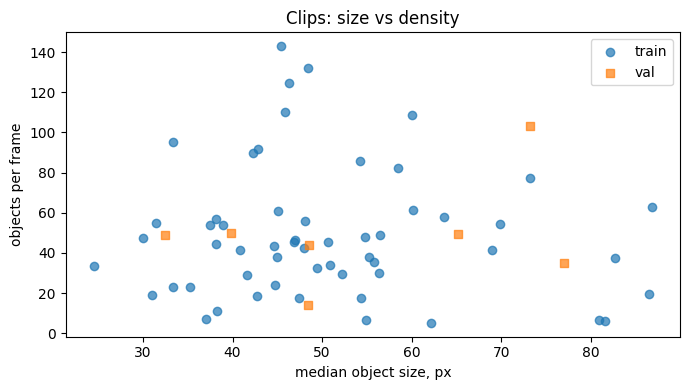

test resolutions: {(680, 382): 3, (960, 540): 5, (1344, 756): 7, (1360, 764): 18, (1904, 1072): 4, (1920, 1080): 11}


In [7]:
def per_clip(s):
    im, ob = imgs[s], obj[s].assign(size=lambda d: np.sqrt(d.w * d.h))
    g = ob.groupby("clip")
    t = pd.DataFrame({
        "split": s,
        "resolution": im.groupby("clip").apply(lambda d: f"{d.width.iloc[0]}x{d.height.iloc[0]}"),
        "frames": im.groupby("clip").size(),
        "obj/frame": g.size() / im.groupby("clip").size(),
        "median px": g["size"].median(),
        "% small": g.apply(lambda d: (d.w * d.h < 32**2).mean() * 100),
        "top class": g.cls.agg(lambda c: CLASSES[c.mode()[0]]),
    })
    return t
clips = pd.concat([per_clip("train"), per_clip("val")])
display(clips.sort_values("obj/frame", ascending=False).round(1))

plt.figure(figsize=(7, 4))
for s, m in [("train", "o"), ("val", "s")]:
    c = clips[clips.split == s]
    plt.scatter(c["median px"], c["obj/frame"], marker=m, label=s, alpha=.7)
plt.xlabel("median object size, px"); plt.ylabel("objects per frame"); plt.legend(); plt.title("Clips: size vs density")
plt.tight_layout(); plt.savefig(WORK / "eda/clips.png", dpi=120); plt.show()
print("test resolutions:", test.groupby(["width", "height"])["clip"].nunique().to_dict())

## 6. Ignored regions and occlusion

In [8]:
for s in ["train", "val"]:
    ig = anns[s][anns[s].iscrowd == 1]
    area = (ig.w * ig.h / (ig.width * ig.height)).groupby(ig.image_id).sum()
    print(f"{s}: {ig.image_id.nunique() / len(imgs[s]) * 100:.0f}% of frames have ignored regions, "
          f"covering {area.mean() * 100:.1f}% of such a frame on average")
for col in ["occlusion", "truncation"]:
    if col in obj["train"]:
        print(col, obj["train"][col].value_counts(normalize=True).sort_index().mul(100).round(1).to_dict())

occlusion {0.0: 54.3, 1.0: 40.3, 2.0: 5.3}
truncation {0.0: 95.7, 1.0: 4.3}


## 7. Temporal redundancy → frame subsampling step
Neighbouring frames are almost identical. For each tracked object we measure the IoU of its box between frame *t* and *t + k*.
High IoU means frame *t + k* adds little new information for training.

In [9]:
def box_iou(a, b):
    x1 = np.maximum(a[:, 0], b[:, 0]); y1 = np.maximum(a[:, 1], b[:, 1])
    x2 = np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]); y2 = np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)

t = obj["train"].merge(imgs["train"][["image_id", "frame_id"]], on="image_id")[["clip", "track_id", "frame_id", "x", "y", "w", "h"]]
res = {}
for k in [1, 2, 4, 8, 16, 32]:
    m = t.merge(t.assign(frame_id=t.frame_id - k), on=["clip", "track_id", "frame_id"], suffixes=("", "_k"))
    res[k] = float(np.median(box_iou(m[["x", "y", "w", "h"]].values, m[["x_k", "y_k", "w_k", "h_k"]].values))) if len(m) else None
print("median IoU of the same object k frames apart:", {k: (round(v, 2) if v is not None else '-') for k, v in res.items()})

median IoU of the same object k frames apart: {1: 0.9, 2: 0.81, 4: 0.66, 8: 0.44, 16: 0.18, 32: 0.0}


## 8. Visual check: ground truth and ignored regions

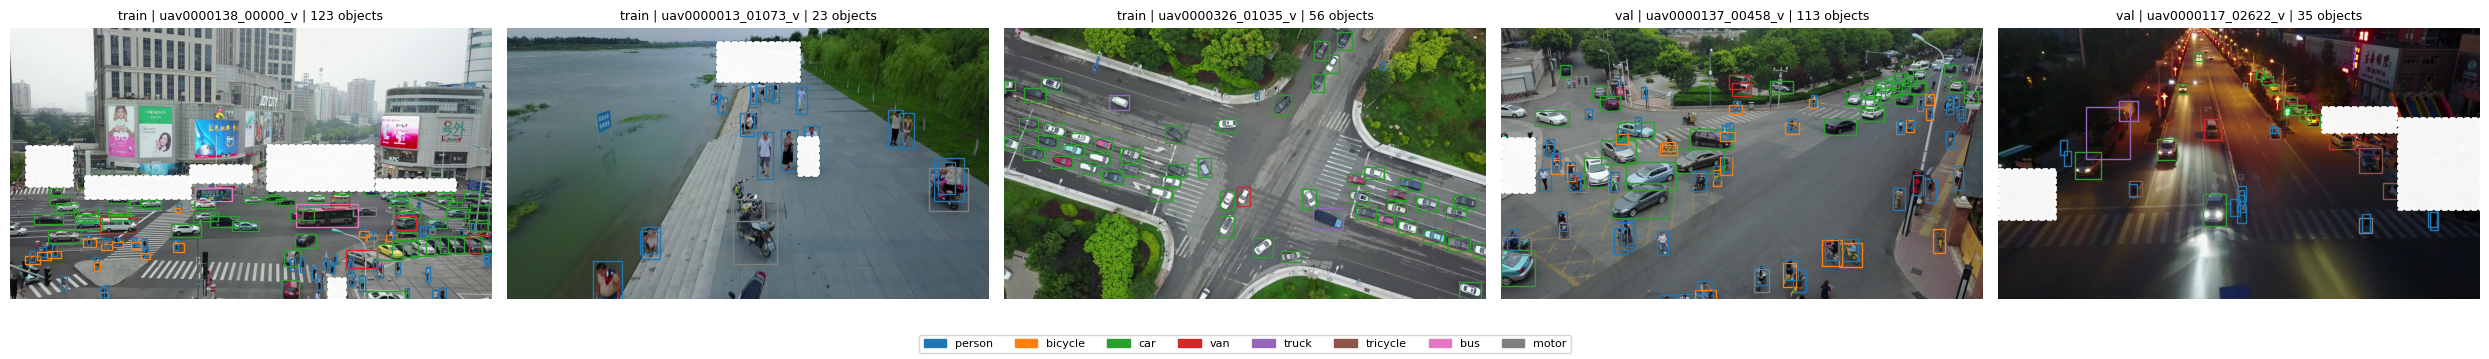

In [10]:
def show_frame(ax, s, image_id):
    im = imgs[s].set_index("image_id").loc[image_id]
    ax.imshow(Image.open(im.path)); ax.axis("off")
    a = anns[s][anns[s].image_id == image_id]
    for r in a.itertuples():
        if r.iscrowd:
            ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fc=(1, 1, 1, .35), ec="w", ls="--"))
        else:
            ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, ec=plt.cm.tab10(r.cls), lw=1))
    ax.set_title(f"{s} | {im['clip']} | {int((a.iscrowd == 0).sum())} objects", fontsize=9)

with_ignore = anns["train"].loc[anns["train"].iscrowd == 1, "image_id"].unique()
picks = [("train", random.choice(list(with_ignore)))] if len(with_ignore) else []
for s in ["train", "val"]:
    for c in random.sample(sorted(imgs[s]["clip"].unique()), 2):
        picks.append((s, imgs[s][imgs[s]["clip"] == c].image_id.sample(1, random_state=SEED).item()))
fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 3.6))
for ax, (s, i) in zip(np.atleast_1d(axes), picks):
    show_frame(ax, s, i)
handles = [patches.Patch(color=plt.cm.tab10(c), label=n) for c, n in enumerate(CLASSES)]
fig.legend(handles=handles, ncol=8, loc="lower center", fontsize=8)
plt.tight_layout(rect=(0, .06, 1, 1)); plt.savefig(WORK / "eda/gt_examples.png", dpi=120); plt.show()

## 9. Conversion to YOLO format
* **Train:** every `STEP`-th frame of each clip (see section 7), all frames of val.
* **Ignored regions** are painted grey (114, the YOLO padding colour), so the model is never told that a crowd is background.
  Boxes whose centre falls inside an ignored region are dropped.
* Images keep their original resolution; resizing happens in the training notebooks.
* Official metrics are computed later with `vd.coco_eval` on the untouched `val/annotations_coco.json`,
  where ignored regions are `iscrowd=1` and are skipped by the evaluator.

In [11]:
STEP = 4                  # train frame step, chosen from the IoU table in section 7
OUT = WORK / "vd_yolo"

def inside(cx, cy, ig):
    return ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
            (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)

def convert(split, step):
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True); (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)
    im = imgs[split].sort_values(["clip", "frame_id"])
    im = im[im.groupby("clip").cumcount() % step == 0]
    by_img = dict(tuple(anns[split].groupby("image_id")))
    kept = dropped = 0
    for r in im.itertuples():
        a = by_img.get(r.image_id, anns[split].iloc[:0])
        ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values
        ob = a[a.iscrowd == 0]
        name = f"{r.clip}_{Path(r.file_name).stem}"
        dst = OUT / "images" / split / f"{name}.jpg"
        if len(ig):
            img = Image.open(r.path).convert("RGB"); px = np.array(img)
            for x, y, w, h in ig.round().astype(int):
                px[max(y, 0):y + h, max(x, 0):x + w] = 114
            Image.fromarray(px).save(dst, quality=95)
            keep = ~inside((ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values, ig)
            dropped += int((~keep).sum()); ob = ob[keep]
        else:
            shutil.copy(r.path, dst)
        kept += len(ob)
        cx = (ob.x + ob.w / 2) / r.width; cy = (ob.y + ob.h / 2) / r.height
        lines = [f"{c} {a_:.6f} {b_:.6f} {w_:.6f} {h_:.6f}" for c, a_, b_, w_, h_ in
                 zip(ob.cls, cx, cy, ob.w / r.width, ob.h / r.height)]
        (OUT / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    print(f"{split}: {len(im)} frames, {kept} boxes, {dropped} boxes dropped inside ignored regions")
    return im

t0 = time.time()
sel = {"train": convert("train", STEP), "val": convert("val", 1)}
(OUT / "data.yaml").write_text(f"path: {OUT}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
pd.concat(sel).to_csv(OUT / "frames.csv", index=False)
print(f"done in {time.time() - t0:.0f}s ->", OUT)

done in 392s -> /kaggle/working/vd_yolo


## 10. Verify the conversion
Read the written YOLO labels back and draw them on the masked images.

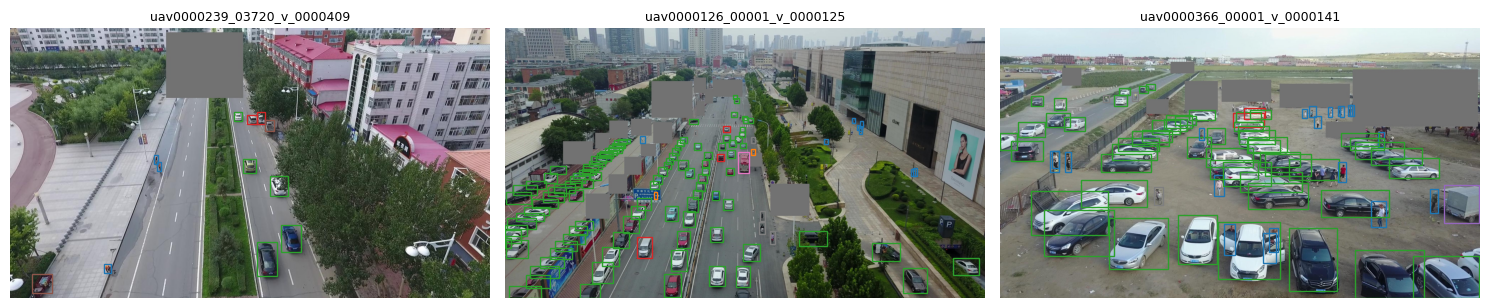

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, p in zip(axes, random.sample(sorted((OUT / "labels" / "train").glob("*.txt")), 3)):
    img = Image.open(OUT / "images" / "train" / f"{p.stem}.jpg"); W, H = img.size
    ax.imshow(img); ax.axis("off"); ax.set_title(p.stem, fontsize=9)
    for line in p.read_text().splitlines():
        c, cx, cy, w, h = map(float, line.split())
        ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, ec=plt.cm.tab10(int(c)), lw=1))
plt.tight_layout(); plt.savefig(WORK / "eda/yolo_check.png", dpi=120); plt.show()

## 11. Observations → decisions
Each row: what this notebook shows → the choice it led to → where the choice is used.

| # | observation (section) | decision | used in |
|---|---|---|---|
| 1 | Clips are separate scenes; the organisers' val (7 clips) shares no clip with train (1) | validate on the organisers' val; never split frames of one clip between train and val (leakage) | all |
| 2 | Same object, IoU between frames *t* and *t+k*: 0.90 (k=1), 0.66 (k=4), 0.44 (k=8) (7) | train on every 4th frame (6 072 frames) for YOLO / RT-DETR; every 8th (3 036) for the ~3× slower torchvision models | 02–09 |
| 3 | Class imbalance: car 45.7 %, person 29.7 %, bus 0.9 % of train objects; val is person-heavy (44.1 % person, 27.9 % car) (2) | report per-class AP (mAP weighs the 8 classes equally, so rare classes matter); treat val conclusions with care — val ≠ train composition | 03–09 |
| 4 | Small objects: median 45.8 px, 24.9 % < 32² px; ≈30 px median at a 720 px short side (3) | input 1280 px instead of 640; 1536 tried; extra P2 head; tiled inference at test time | 02, 05, 07 |
| 5 | The smallest default anchor (32 px) is larger than the median object at the model input (3) | RetinaNet anchors shifted to 16–256 px | 04 |
| 6 | Wide size range per class: bus median 113 px (57 % large), person 36 px (40 % small) (3) | FPN-based multi-scale models; AP reported by object size | 03–07 |
| 7 | Dense scenes: median 43, max 180 objects per train frame (4) | max_det = 500 in every model and in the evaluator (COCO default 100 is too low); RT-DETR queries 300 vs 500 | 02–07 |
| 8 | Clips differ in resolution (train up to 2688×1512; test 680×382 … 1920×1080, mostly 1360×764) and density (≈5–143 objects/frame) (5) | fixed model input (letterbox 1280 / short side 720), evaluation on original frames; the 7-clip val is a noisy estimate | all |
| 9 | Ignored regions in 75 % of train frames (50 % of val), ≈26 % of such a frame (6) | paint them grey (114) in training images and drop boxes centred inside (3 274 train boxes); keep `iscrowd` for evaluation so detections there are not false positives | 01, `vd_utils` |
| 10 | 40 % of objects partly and 5 % heavily occluded (6) | expect misses in crowds; analysed in the failure cases of notebook 03 | 03 |
| 11 | Ground truth, ignored regions and the written YOLO labels line up with the objects (8, 10) | conversion accepted as correct | — |